# RIMER：完整与不完整输入的证据推理
复现 Yang 等（2006）第 V 节石墨容器系统，规则来自 Table II（36 条）。
[论文 PDF](https://personalpages.manchester.ac.uk/staff/jian-bo.yang/JB%20Yang%20Journal_Papers/JBYang-RIME-IEEESMC.pdf)，DOI 10.1109/TSMCA.2005.851270。
这篇论文的主例是推理示范，训练参见前一个 notebook。
源码：[规则与参考结果](../paper_cases/graphite.json)、[ER 推理](../../brb/rimer/inference.py)。
本文正文与 Table II 对第 13 条规则存在差异；采用表格 beta=[0.2,0.8,0]。

## 1. 运行环境

In [1]:
from pathlib import Path
import sys, platform
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'brb' / 'rimer').is_dir())
sys.path.insert(0, str(root))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.random.seed(2026)
pd.set_option('display.precision', 6)
print('Python:', platform.python_version())
print('Toolkit root located.')


Python: 3.12.14
Toolkit root located.


## 2. 论文第 3 组输入

In [2]:
from examples.paper_cases.graphite import load_graphite_case, build_graphite_model, graphite_inputs
case = load_graphite_case(); raw = np.asarray(case['training'][2][:4])
display(pd.DataFrame([raw],columns=case['column_order'][:4]))
model = build_graphite_model()
assert sum(len(m.config.rule_weights) for m in model.models.values()) == 36

,X3,X1,X5,X7
0,0.98,0.8,0.2,0.8


## 3. 将数值转换为 H/M/L 信念
线性插值使用参考值 [1,0.5,0]。

In [3]:
inputs = graphite_inputs(raw)
display(pd.DataFrame({k:v[0] for k,v in inputs.items()},index=['H','M','L']).T)

,H,M,L
X3,0.96,0.04,0.0
X1,0.60,0.40,0.0
X5,0.00,0.40,0.6
X7,0.60,0.40,0.0


## 4. 匹配与规则激活

In [4]:
complete = model.infer(inputs)
x6 = complete.trace['X6']
display(pd.DataFrame({'rule':range(10,19),'activation':x6.activation[0],'input_completeness':x6.completeness[0]}))
np.testing.assert_allclose(x6.activation.sum(1),1)

,rule,activation,input_completeness
0,10,0.000000,1.0
1,11,0.000000,1.0
2,12,0.000000,1.0
3,13,0.693421,1.0
4,14,0.020748,1.0
5,15,0.000000,1.0
6,16,0.208026,1.0
7,17,0.077805,1.0
8,18,0.000000,1.0


## 5. 对照中间节点的纸面数值
参考结果独立转录；中间节点容差为 5×10⁻⁵。

In [5]:
rows=[]
for node in ['X2','X4','X6','X8']:
    computed = complete.trace[node].beliefs[0]
    paper_reference = np.asarray(case['paper_reference'][node])
    np.testing.assert_allclose(computed,paper_reference,atol=5e-5,rtol=0)
    for state,a,b in zip(['H','M','L'],computed,paper_reference): rows.append([node,state,a,b,abs(a-b)])
display(pd.DataFrame(rows,columns=['node','state','computed','paper_reference','absolute_error']))

,node,state,computed,paper_reference,absolute_error
0,X2,H,0.692308,0.6923,7.692308e-06
1,X2,M,0.307692,0.3077,7.692308e-06
2,X2,L,0.000000,0.0000,0.000000e+00
3,X4,H,0.930403,0.9304,3.408869e-06
4,X4,M,0.069597,0.0696,3.408869e-06
5,X4,L,0.000000,0.0000,0.000000e+00
6,X6,H,0.170700,0.1707,3.988201e-07
7,X6,M,0.747263,0.7473,3.704531e-05
8,X6,L,0.082037,0.0820,3.664649e-05
9,X8,H,0.745897,0.7459,3.045019e-06


## 6. 完整输出 X9
原文报告 H/M/L=0.2685/0.6772/0.0543，置信度 0.6071。最终容差 10⁻⁴，反映纸面递归舍入。

In [6]:
paper_reference=np.array([.2685,.6772,.0543])
computed=complete.beliefs[0]
display(pd.DataFrame({'computed':computed,'paper_reference':paper_reference},index=['H','M','L']))
np.testing.assert_allclose(computed,paper_reference,atol=1e-4,rtol=0)
print('Confidence:', complete.expected_value([1,.5,0])[0])

,computed,paper_reference
H,0.268564,0.2685
M,0.677169,0.6772
L,0.054266,0.0543


Confidence: 0.6071492180339607


## 7. 输入不完整：X5 只有 80% 的低等级信念
剩余 20% 是未知，不能归一化掉。

In [7]:
incomplete_inputs={k:v.copy() for k,v in inputs.items()}
incomplete_inputs['X5']=np.array([[0,0,.8]])
incomplete=model.infer(incomplete_inputs)
display(pd.DataFrame({'H':[incomplete.trace['X6'].beliefs[0,0],incomplete.beliefs[0,0]],
    'M':[incomplete.trace['X6'].beliefs[0,1],incomplete.beliefs[0,1]],
    'L':[incomplete.trace['X6'].beliefs[0,2],incomplete.beliefs[0,2]],
    'Unknown':[incomplete.trace['X6'].ignorance[0],incomplete.ignorance[0]]},index=['X6','X9']))

,H,M,L,Unknown
X6,0.067925,0.240216,0.606209,0.085649
X9,0.115095,0.248005,0.599813,0.037087


## 8. 不完整输出对照与效用区间
有 Unknown 时，直接取期望需要用户明确选择决策策略；这里报告上下界。

In [8]:
computed=np.r_[incomplete.beliefs[0],incomplete.ignorance[0]]
paper_reference=np.r_[case['paper_reference']['X9_incomplete'],case['paper_reference']['X9_unknown']]
display(pd.DataFrame({'computed':computed,'paper_reference':paper_reference,'absolute_error':abs(computed-paper_reference)},index=['H','M','L','Unknown']))
np.testing.assert_allclose(computed,paper_reference,atol=5e-5,rtol=0)
print('Utility lower/upper:', incomplete.utility_interval[0])

,computed,paper_reference,absolute_error
H,0.115095,0.1151,0.000005
M,0.248005,0.2480,0.000005
L,0.599813,0.5998,0.000013
Unknown,0.037087,0.0371,0.000013


Utility lower/upper: [0.23909744 0.27618474]


## 9. 最终质量图

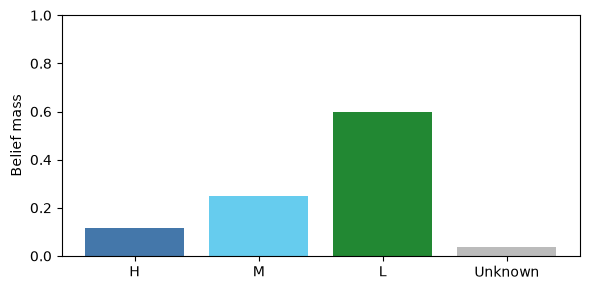

In [9]:
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(['H','M','L','Unknown'],computed,color=['#4477aa','#66ccee','#228833','#bbbbbb'])
ax.set(ylabel='Belief mass',ylim=(0,1));fig.tight_layout();plt.show()

## 10. 验收
验证的是给定规则与输入的推理路径，以及未知质量的传播。

In [10]:
np.testing.assert_allclose(incomplete.beliefs.sum(1)+incomplete.ignorance,1,atol=1e-12)
assert incomplete.ignorance[0]>0
print('Verified: complete inference and incomplete X9 with Unknown ≈ 0.0371.')

Verified: complete inference and incomplete X9 with Unknown ≈ 0.0371.
